# 04 — Classificação: categoria de crescimento do PIB

**Trabalho 2 – Previsão do PIB dos Municípios da Região Sul (PR, SC, RS)**

Objetivo: prever em qual das 5 categorias de crescimento do enunciado cada município cai. Este notebook cobre a **Etapa A**: escolher e avaliar os modelos com dados até 2022 e testar contra as categorias oficiais de 2023.
A previsão de 2024 (Etapa B) fica no notebook 05.

| Categoria | Crescimento do PIB em relação ao ano anterior |
|---|---|
| Forte retração | < -5% |
| Retração | -5% a -1% |
| Estabilidade | -1% a 1% |
| Crescimento moderado | 1% a 5% |
| Forte crescimento | > 5% |

**Métricas exigidas:** F1-score e matriz de confusão. Usamos o **F1 macro**, a média simples do F1 das 5 classes, como critério principal, porque as classes são muito desbalanceadas (notebook 02).
Também reportamos o F1 ponderado pela frequência, a acurácia e a **acurácia adjacente** (acerto exato ou erro de uma só categoria vizinha). As classes são ordenadas, então errar por uma faixa é bem menos grave do que confundir retração com crescimento.

## Estratégia

| Item | Escolha |
|---|---|
| Abordagem 1 | **Regressão → categoria**: o crescimento previsto pelo ensemble da Fase 4 é convertido nas 5 faixas. A categoria fica coerente com o PIB previsto. |
| Abordagem 2 | **Classificadores diretos**: Regressão Logística multinomial, Random Forest e LightGBM, com e sem pesos inversos à frequência das classes (`class_weight`) |
| Baselines | classe majoritária do treino; categoria do próprio município no ano anterior |
| Validação | a mesma da regressão: janela expansiva, validação em 2019, 2020, 2021 e 2022 |
| Escolha | par (modelo, janela de treino) com **maior F1 macro médio** na validação |
| Teste final | treina com alvos até 2022 e prevê 2023, que **não entra em nenhuma escolha** |

In [1]:
import sys, json, time, warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

from src import features as ft
from src import modelos as m
from src import viz

viz.aplica_estilo()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

DIR_RES = RAIZ / "reports" / "resultados"
DIR_PRED = RAIZ / "data" / "predictions"
CATS = ft.CATEGORIAS

dataset = ft.carrega_dataset()
numericas, categoricas = ft.colunas_modelo(dataset)
config_reg = json.loads((DIR_RES / "config_regressao.json").read_text(encoding="utf-8"))
PARAMS_ENSEMBLE = config_reg["hiperparametros"][m.NOME_ENSEMBLE]
INICIO_PADRAO = ft.PRIMEIRO_ANO_AMOSTRA_PADRAO
print(f"Dataset: {dataset.shape} | {len(numericas)} numéricas + {len(categoricas)} categóricas")
print(f"Regressão da Fase 4: {config_reg['melhor_modelo']}, alvos a partir de {config_reg['inicio_janela']}")

Dataset: (20247, 58) | 39 numéricas + 3 categóricas
Regressão da Fase 4: Ensemble (Ridge + RF + LightGBM), alvos a partir de 2016


## 1. As classes nos anos de validação e de teste

A distribuição muda muito de um ano para outro. Isso pesa mais do que o desbalanceamento médio: o modelo precisa acertar o "clima" do ano, e não só o perfil de cada município.

In [2]:
dist = (pd.crosstab(dataset["ano"], dataset["categoria_crescimento"], normalize="index") * 100).loc[2016:2023]
dist["municípios"] = dataset[dataset["ano"].between(2016, 2023)].groupby("ano").size()
dist

categoria_crescimento,Forte retração,Retração,Estabilidade,Crescimento moderado,Forte crescimento,municípios
ano,,,,,,
2016,3.023,5.038,4.282,14.106,73.552,1191
2017,17.128,14.274,8.312,16.961,43.325,1191
2018,7.641,9.236,6.717,20.487,55.919,1191
2019,10.160,12.427,9.320,19.563,48.531,1191
2020,12.427,7.473,5.709,12.175,62.217,1191
2021,2.687,1.763,1.175,5.709,88.665,1191
2022,33.585,7.053,4.366,9.236,45.760,1191
2023,7.137,4.366,2.519,7.473,78.505,1191


## 2. Baselines

In [3]:
res_base = {nome: m.valida_temporal_classificacao(nome, {}, dataset, INICIO_PADRAO) for nome in m.BASELINES_CLASSIFICACAO}
pd.concat({n: r.por_ano.drop(columns="n_treino") for n, r in res_base.items()}, axis=0).round(3)

F1_macro  F1_ponderado  Acuracia  Acuracia_adjacente
                             ano_validacao                                                      
Classe majoritária do treino 2019              0.131         0.317     0.485               0.681
                             2020              0.153         0.477     0.622               0.744
                             2021              0.188         0.833     0.887               0.944
                             2022              0.126         0.287     0.458               0.550
Categoria do ano anterior    2019              0.171         0.276     0.291               0.573
                             2020              0.188         0.348     0.323               0.568
                             2021              0.165         0.629     0.540               0.703
                             2022              0.161         0.292     0.407               0.525

A **classe majoritária** (sempre "Forte crescimento") tem acurácia de 61%, mas F1 macro de só 0,15: acerta a classe dominante e erra todas as outras.
Esse é o motivo de não usar a acurácia como critério. Repetir a **categoria do ano anterior** é ainda pior na acurácia, porque o crescimento nominal reverte com frequência (notebook 02).

## 3. Busca de hiperparâmetros dos classificadores diretos (alvos a partir de 2013)

In [4]:
t0 = time.time()
buscas = {}
for nome in m.FABRICAS_CLASSIFICACAO:
    print(f"== {nome}: {len(m.combinacoes(m.GRADES_CLASSIFICACAO[nome]))} combinações × {len(m.ANOS_VALIDACAO)} anos")
    buscas[nome] = m.busca_classificacao(nome, dataset, INICIO_PADRAO, verbose=False)
    melhor = buscas[nome].iloc[0]
    print(f"   melhor: {melhor['params']}  ->  F1 macro {melhor['F1_macro']:.3f}")
print(f"Tempo total: {(time.time() - t0) / 60:.1f} min")

tabela_busca = pd.concat(buscas.values(), ignore_index=True)
tabela_busca.assign(params=tabela_busca["params"].astype(str)).to_csv(DIR_RES / "classificacao_busca_hiperparametros.csv", index=False)
for nome, tab in buscas.items():
    print(f"\n{nome}")
    display(tab[["params", "F1_macro", "F1_macro_pior_ano", "F1_ponderado", "Acuracia", "Acuracia_adjacente"]])

== Regressão Logística: 6 combinações × 4 anos


   melhor: {'C': 0.01, 'class_weight': 'balanced'}  ->  F1 macro 0.303
== Random Forest (clf): 8 combinações × 4 anos


   melhor: {'min_samples_leaf': 20, 'max_features': 0.6, 'class_weight': 'balanced_subsample'}  ->  F1 macro 0.335
== LightGBM (clf): 8 combinações × 4 anos


   melhor: {'num_leaves': 31, 'min_child_samples': 60, 'class_weight': 'balanced'}  ->  F1 macro 0.342
Tempo total: 2.3 min

Regressão Logística


,params,F1_macro,F1_macro_pior_ano,F1_ponderado,Acuracia,Acuracia_adjacente
0,"{'C': 0.01, 'class_weight': 'balanced'}",0.303,0.258,0.587,0.601,0.791
1,"{'C': 0.1, 'class_weight': None}",0.296,0.228,0.626,0.674,0.826
2,"{'C': 1.0, 'class_weight': None}",0.291,0.237,0.621,0.665,0.815
3,"{'C': 0.1, 'class_weight': 'balanced'}",0.285,0.255,0.564,0.577,0.771
4,"{'C': 0.01, 'class_weight': None}",0.284,0.230,0.622,0.683,0.834
5,"{'C': 1.0, 'class_weight': 'balanced'}",0.282,0.253,0.560,0.573,0.765



Random Forest (clf)


,params,F1_macro,F1_macro_pior_ano,F1_ponderado,Acuracia,Acuracia_adjacente
0,"{'min_samples_leaf': 20, 'max_features': 0.6, ...",0.335,0.294,0.624,0.639,0.823
1,"{'min_samples_leaf': 5, 'max_features': 0.6, '...",0.329,0.267,0.645,0.682,0.847
2,"{'min_samples_leaf': 20, 'max_features': 0.33,...",0.323,0.255,0.623,0.642,0.824
3,"{'min_samples_leaf': 5, 'max_features': 0.33, ...",0.315,0.227,0.643,0.684,0.843
4,"{'min_samples_leaf': 5, 'max_features': 0.6, '...",0.301,0.222,0.635,0.703,0.838
5,"{'min_samples_leaf': 20, 'max_features': 0.6, ...",0.298,0.221,0.632,0.705,0.834
6,"{'min_samples_leaf': 20, 'max_features': 0.33,...",0.290,0.200,0.629,0.707,0.835
7,"{'min_samples_leaf': 5, 'max_features': 0.33, ...",0.287,0.200,0.628,0.703,0.834



LightGBM (clf)


,params,F1_macro,F1_macro_pior_ano,F1_ponderado,Acuracia,Acuracia_adjacente
0,"{'num_leaves': 31, 'min_child_samples': 60, 'c...",0.342,0.311,0.647,0.679,0.845
1,"{'num_leaves': 15, 'min_child_samples': 60, 'c...",0.339,0.277,0.635,0.651,0.837
2,"{'num_leaves': 15, 'min_child_samples': 20, 'c...",0.327,0.246,0.630,0.645,0.829
3,"{'num_leaves': 31, 'min_child_samples': 20, 'c...",0.326,0.243,0.644,0.680,0.847
4,"{'num_leaves': 31, 'min_child_samples': 20, 'c...",0.314,0.240,0.643,0.704,0.844
5,"{'num_leaves': 15, 'min_child_samples': 60, 'c...",0.313,0.251,0.641,0.703,0.842
6,"{'num_leaves': 31, 'min_child_samples': 60, 'c...",0.311,0.246,0.640,0.703,0.841
7,"{'num_leaves': 15, 'min_child_samples': 20, 'c...",0.309,0.230,0.638,0.701,0.840


## 4. Janela de treino e escolha do modelo

Como na regressão, a janela é um hiperparâmetro: repetimos a validação com alvos a partir de 2010, 2013 e 2016 e escolhemos o **par (modelo, janela) com maior F1 macro médio**.
A abordagem **Regressão → categoria** entra na mesma comparação, com o ensemble e os hiperparâmetros da Fase 4, treinado em cada janela.

In [5]:
melhores = {nome: tab.iloc[0]["params"] for nome, tab in buscas.items()}
params_modelos = {**melhores, m.NOME_REG_CATEGORIA: PARAMS_ENSEMBLE}
janelas = {}
for inicio in [2010, 2013, 2016]:
    for nome, p in params_modelos.items():
        janelas[(nome, inicio)] = m.valida_temporal_classificacao(nome, p, dataset, inicio).media["F1_macro"]
tab_janelas = pd.Series(janelas).unstack()
melhor_modelo, inicio_escolhido = tab_janelas.stack().idxmax()
inicio_escolhido = int(inicio_escolhido)
tab_janelas.columns = [f"início {c}" for c in tab_janelas.columns]
print(f"Melhor par na validação: {melhor_modelo} com alvos a partir de {inicio_escolhido} "
      f"(F1 macro médio {tab_janelas.max().max():.3f})")
tab_janelas.round(3)

Melhor par na validação: Random Forest (clf) com alvos a partir de 2010 (F1 macro médio 0.347)


,início 2010,início 2013,início 2016
LightGBM (clf),0.338,0.342,0.332
Random Forest (clf),0.347,0.335,0.346
Regressão Logística,0.312,0.303,0.304
Regressão → categoria (Ensemble),0.323,0.344,0.343


## 5. Comparação dos modelos na janela escolhida

In [6]:
res_val = {nome: m.valida_temporal_classificacao(nome, {}, dataset, inicio_escolhido) for nome in m.BASELINES_CLASSIFICACAO}
for nome, p in params_modelos.items():
    res_val[nome] = m.valida_temporal_classificacao(nome, p, dataset, inicio_escolhido)

comparacao_val = pd.DataFrame({
    nome: {**r.media.drop("n_treino").to_dict(), "F1_macro_pior_ano": r.por_ano["F1_macro"].min()}
    for nome, r in res_val.items()
}).T.sort_values("F1_macro", ascending=False)
comparacao_val.to_csv(DIR_RES / "classificacao_validacao_comparacao.csv")
display(pd.concat({n: r.por_ano["F1_macro"] for n, r in res_val.items()}, axis=1).T.loc[comparacao_val.index]
        .rename(columns=lambda a: f"F1 macro {a}"))
comparacao_val[["F1_macro", "F1_macro_pior_ano", "F1_ponderado", "Acuracia", "Acuracia_adjacente"]]

ano_validacao,F1 macro 2019,F1 macro 2020,F1 macro 2021,F1 macro 2022
Random Forest (clf),0.359,0.374,0.314,0.340
LightGBM (clf),0.340,0.356,0.302,0.354
Regressão → categoria (Ensemble),0.335,0.364,0.212,0.381
Regressão Logística,0.295,0.351,0.282,0.320
Categoria do ano anterior,0.171,0.188,0.165,0.161
Classe majoritária do treino,0.131,0.153,0.188,0.126


,F1_macro,F1_macro_pior_ano,F1_ponderado,Acuracia,Acuracia_adjacente
Random Forest (clf),0.347,0.314,0.636,0.648,0.843
LightGBM (clf),0.338,0.302,0.645,0.672,0.844
Regressão → categoria (Ensemble),0.323,0.212,0.647,0.677,0.852
Regressão Logística,0.312,0.282,0.595,0.607,0.821
Categoria do ano anterior,0.171,0.161,0.386,0.390,0.592
Classe majoritária do treino,0.149,0.126,0.479,0.613,0.730


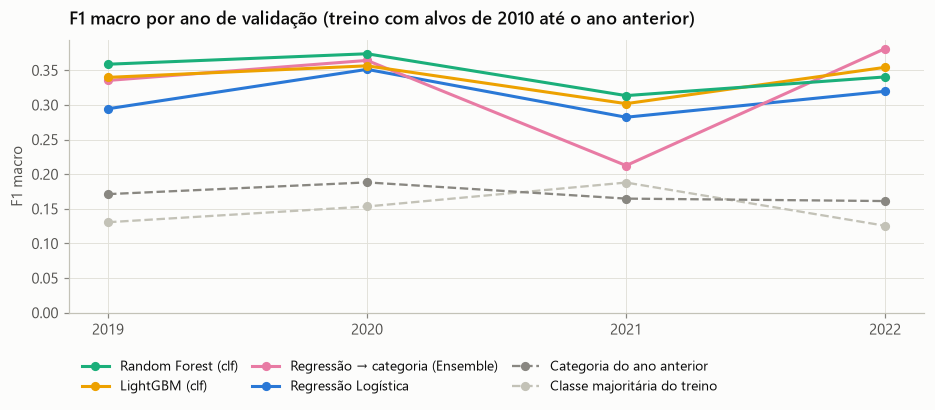

In [7]:
fig, ax = plt.subplots(figsize=(8.6, 3.9))
for nome in comparacao_val.index[::-1]:
    serie = res_val[nome].por_ano["F1_macro"]
    base = nome in m.BASELINES_CLASSIFICACAO
    ax.plot(serie.index, serie.values, color=viz.CORES_CLASSIFICADORES[nome], lw=1.5 if base else 2,
            ls="--" if base else "-", marker="o", ms=5, label=nome)
ax.set_xticks(m.ANOS_VALIDACAO)
ax.set_ylabel("F1 macro")
ax.set_ylim(0, None)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], ncol=3, loc="upper left", bbox_to_anchor=(0, -0.13), columnspacing=1.0)
ax.set_title(f"F1 macro por ano de validação (treino com alvos de {inicio_escolhido} até o ano anterior)")
fig.tight_layout()
viz.salva_figura(fig, "clf_validacao_f1_por_ano")
plt.show()

In [8]:
assert melhor_modelo == comparacao_val.drop(index=list(m.BASELINES_CLASSIFICACAO)).index[0]  # mesma escolha da seção 4
print(f"Modelo escolhido: {melhor_modelo} | F1 macro médio na validação: {comparacao_val.loc[melhor_modelo, 'F1_macro']:.3f}")

config = {
    "melhor_modelo": melhor_modelo,
    "inicio_janela": inicio_escolhido,
    "hiperparametros": params_modelos,
    "criterio": "F1 macro médio na validação temporal 2019–2022",
}
_ = (DIR_RES / "config_classificacao.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

Modelo escolhido: Random Forest (clf) | F1 macro médio na validação: 0.347


## 6. Teste final em 2023 (Etapa A)

Todos os modelos são treinados com alvos de **início a 2022**, na janela escolhida, e preveem a categoria de 2023. A comparação é com a **categoria calculada a partir do PIB oficial de 2023**.

In [9]:
treino = m.amostra_modelagem(dataset, inicio_escolhido, 2022)
teste = m.amostra_modelagem(dataset, m.ANO_TESTE, m.ANO_TESTE)
y_teste = m.codigos_categoria(teste["categoria_crescimento"])
print(f"Treino: {len(treino):,} linhas (alvos {treino['ano'].min()}–{treino['ano'].max()}) | Teste: {len(teste):,} municípios")

prev_teste = {nome: m.preve_categoria(nome, {}, treino, teste, numericas, categoricas) for nome in m.BASELINES_CLASSIFICACAO}
for nome, p in params_modelos.items():
    prev_teste[nome] = m.preve_categoria(nome, p, treino, teste, numericas, categoricas)

resultado_teste = pd.DataFrame({n: m.metricas_classificacao(y_teste, p) for n, p in prev_teste.items()}).T
resultado_teste = resultado_teste.sort_values("F1_macro", ascending=False)
resultado_teste.to_csv(DIR_RES / "classificacao_teste_2023.csv")
resultado_teste

Treino: 15,471 linhas (alvos 2010–2022) | Teste: 1,191 municípios


,F1_macro,F1_ponderado,Acuracia,Acuracia_adjacente
Regressão → categoria (Ensemble),0.358,0.706,0.651,0.868
LightGBM (clf),0.304,0.635,0.566,0.802
Random Forest (clf),0.275,0.604,0.530,0.796
Regressão Logística,0.221,0.459,0.354,0.501
Classe majoritária do treino,0.176,0.691,0.785,0.860
Categoria do ano anterior,0.172,0.480,0.407,0.554


In [10]:
# Coerência com a Fase 4: na janela da regressão, a abordagem 1 reproduz as categorias do PIB previsto em 2023
if inicio_escolhido == config_reg["inicio_janela"]:
    reg23 = pd.read_csv(DIR_PRED / "regressao_teste_2023_todos_modelos.csv").set_index("cod_ibge").loc[teste["cod_ibge"]]
    cat_reg = m.categoria_de_log(np.log(reg23["pib_prev_ensemble"] / reg23["pib_l1"]))
    print("Categorias iguais às do PIB previsto na Fase 4:", np.mean(cat_reg == prev_teste[m.NOME_REG_CATEGORIA]) * 100, "%")

# Previsões de 2023 de todos os modelos
saida = teste[["cod_ibge", "municipio", "uf", "ano", "cresc_pib_pct", "categoria_crescimento"]].copy()
chaves = {"Classe majoritária do treino": "majoritaria", "Categoria do ano anterior": "ano_anterior",
          "Regressão Logística": "logistica", "Random Forest (clf)": "random_forest",
          "LightGBM (clf)": "lightgbm", m.NOME_REG_CATEGORIA: "regressao_ensemble"}
for nome, p in prev_teste.items():
    saida[f"cat_prev_{chaves[nome]}"] = pd.Categorical.from_codes(p, categories=CATS, ordered=True)
saida.to_csv(DIR_PRED / "classificacao_teste_2023_todos_modelos.csv", index=False)
print("Gravado:", (DIR_PRED / "classificacao_teste_2023_todos_modelos.csv").name)

Gravado: classificacao_teste_2023_todos_modelos.csv


### 6.1 Matriz de confusão do modelo escolhido

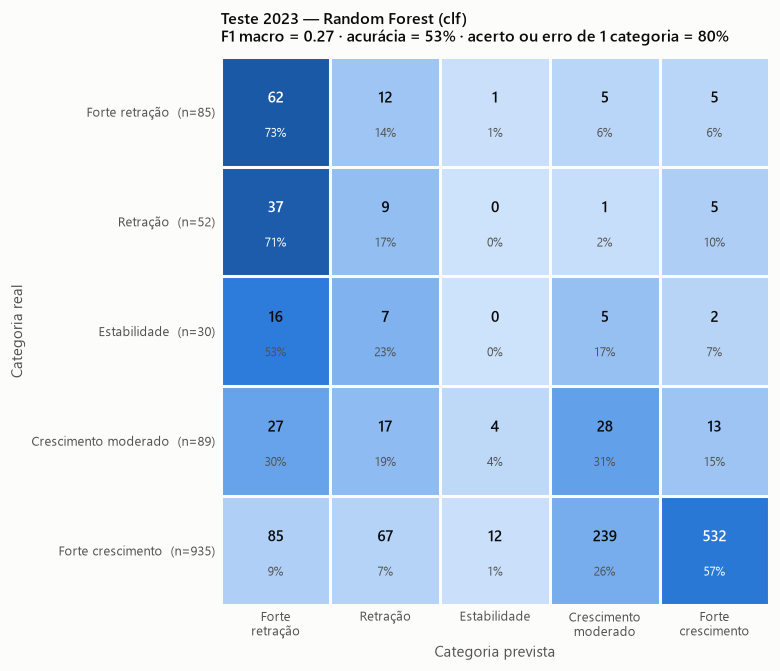

                      precision    recall  f1-score   support

      Forte retração      0.273     0.729     0.397        85
            Retração      0.080     0.173     0.110        52
        Estabilidade      0.000     0.000     0.000        30
Crescimento moderado      0.101     0.315     0.153        89
   Forte crescimento      0.955     0.569     0.713       935

            accuracy                          0.530      1191
           macro avg      0.282     0.357     0.275      1191
        weighted avg      0.780     0.530     0.604      1191



In [11]:
p_best = prev_teste[melhor_modelo]
cm = confusion_matrix(y_teste, p_best, labels=range(len(CATS)))
met = resultado_teste.loc[melhor_modelo]

fig, ax = plt.subplots(figsize=(7.6, 6.2))
viz.matriz_confusao(cm, CATS, ax=ax)
ax.set_title(f"Teste 2023 — {melhor_modelo}\nF1 macro = {met['F1_macro']:.2f} · acurácia = {met['Acuracia'] * 100:.0f}% · "
             f"acerto ou erro de 1 categoria = {met['Acuracia_adjacente'] * 100:.0f}%", fontsize=10.5)
fig.tight_layout()
viz.salva_figura(fig, "fig_matriz_confusao_2023")
plt.show()

print(classification_report(y_teste, p_best, labels=range(len(CATS)), target_names=CATS, zero_division=0, digits=3))

### 6.2 Distribuição prevista × real e erros por UF

In [12]:
contagem = pd.DataFrame({"real": pd.Series(y_teste).value_counts(),
                         **{n: pd.Series(p).value_counts() for n, p in prev_teste.items()
                            if n not in m.BASELINES_CLASSIFICACAO}}).reindex(range(len(CATS))).fillna(0).astype(int)
contagem.index = CATS
display(contagem)

analise = teste[["cod_ibge", "municipio", "uf", "porte", "cresc_pib_pct"]].copy()
analise["real"], analise["prevista"] = y_teste, p_best
analise["distancia"] = analise["prevista"] - analise["real"]
por_uf = analise.groupby("uf").agg(municipios=("real", "size"),
                                   acerto_exato=("distancia", lambda d: (d == 0).mean()),
                                   acerto_adjacente=("distancia", lambda d: (d.abs() <= 1).mean()),
                                   previu_abaixo=("distancia", lambda d: (d < 0).mean()),
                                   previu_acima=("distancia", lambda d: (d > 0).mean()))
por_uf["F1_macro"] = [m.metricas_classificacao(g["real"], g["prevista"])["F1_macro"] for _, g in analise.groupby("uf")]
por_uf

,real,Regressão Logística,Random Forest (clf),LightGBM (clf),Regressão → categoria (Ensemble)
Forte retração,85,192,227,194,95
Retração,52,86,112,110,94
Estabilidade,30,499,17,47,64
Crescimento moderado,89,58,278,230,209
Forte crescimento,935,356,557,610,729


,municipios,acerto_exato,acerto_adjacente,previu_abaixo,previu_acima,F1_macro
uf,,,,,,
PR,399,0.669,0.845,0.308,0.023,0.311
RS,497,0.370,0.759,0.584,0.046,0.257
SC,295,0.610,0.793,0.332,0.058,0.194


## 7. Escolha para a Etapa B (validação 2019–2023)

Na Etapa A, os três melhores candidatos ficaram praticamente empatados na validação (F1 macro entre 0,34 e 0,35), mas se separaram no teste de 2023.
Na Etapa B, que prevê 2024, **o ano de 2023 já é conhecido** e pode entrar na escolha. Por isso repetimos **o mesmo protocolo**, agora com 5 anos de validação (2019 a 2023):

1. busca de hiperparâmetros dos classificadores diretos (alvos a partir de 2013);
2. escolha conjunta de (modelo, janela) entre os inícios 2010, 2013 e 2016, incluindo a abordagem Regressão → categoria;
3. critério: **maior F1 macro médio**.

A regra foi definida antes de rodar esta seção. O resultado da Etapa A (seção 6) não muda: ele continua sendo a avaliação honesta do modelo escolhido sem ver 2023.

In [13]:
ANOS_B = m.ANOS_VALIDACAO_ETAPA_B
t0 = time.time()
buscas_b = {nome: m.busca_classificacao(nome, dataset, INICIO_PADRAO, anos_validacao=ANOS_B, verbose=False)
            for nome in m.FABRICAS_CLASSIFICACAO}
melhores_b = {nome: tab.iloc[0]["params"] for nome, tab in buscas_b.items()}
params_b = {**melhores_b, m.NOME_REG_CATEGORIA: PARAMS_ENSEMBLE}
for nome, p in melhores_b.items():
    print(f"{nome}: {p} -> F1 macro {buscas_b[nome].iloc[0]['F1_macro']:.3f}")

res_b = {}
for inicio in [2010, 2013, 2016]:
    for nome, p in params_b.items():
        res_b[(nome, inicio)] = m.valida_temporal_classificacao(nome, p, dataset, inicio, ANOS_B)
tab_b = pd.Series({k: r.media["F1_macro"] for k, r in res_b.items()}).unstack()
melhor_b, inicio_b = tab_b.stack().idxmax()
inicio_b = int(inicio_b)
print(f"Tempo: {(time.time() - t0) / 60:.1f} min")
print(f"Escolha da Etapa B: {melhor_b} com alvos a partir de {inicio_b} (F1 macro médio 2019–2023 = {tab_b.max().max():.3f})")
tab_b.columns = [f"início {c}" for c in tab_b.columns]
tab_b.round(3)

Regressão Logística: {'C': 0.1, 'class_weight': None} -> F1 macro 0.298
Random Forest (clf): {'min_samples_leaf': 5, 'max_features': 0.6, 'class_weight': 'balanced_subsample'} -> F1 macro 0.322
LightGBM (clf): {'num_leaves': 31, 'min_child_samples': 60, 'class_weight': 'balanced'} -> F1 macro 0.335


Tempo: 5.4 min
Escolha da Etapa B: Regressão → categoria (Ensemble) com alvos a partir de 2013 (F1 macro médio 2019–2023 = 0.354)


,início 2010,início 2013,início 2016
LightGBM (clf),0.331,0.335,0.329
Random Forest (clf),0.318,0.322,0.334
Regressão Logística,0.288,0.298,0.291
Regressão → categoria (Ensemble),0.330,0.354,0.349


In [14]:
# F1 macro por ano de validação de cada modelo, na sua melhor janela
melhor_janela = {nome: int(tab_b.loc[nome].idxmax().split()[-1]) for nome in tab_b.index}
por_ano_b = pd.DataFrame({f"{nome} (início {ini})": res_b[(nome, ini)].por_ano["F1_macro"]
                          for nome, ini in melhor_janela.items()}).T
por_ano_b["média"] = por_ano_b.mean(axis=1)
por_ano_b = por_ano_b.sort_values("média", ascending=False)
por_ano_b.to_csv(DIR_RES / "classificacao_validacao_etapa_b.csv")
por_ano_b.round(3)

ano_validacao,2019,2020,2021,2022,2023,média
Regressão → categoria (Ensemble) (início 2013),0.354,0.413,0.212,0.397,0.396,0.354
LightGBM (clf) (início 2013),0.361,0.352,0.311,0.345,0.308,0.335
Random Forest (clf) (início 2016),0.352,0.339,0.305,0.359,0.314,0.334
Regressão Logística (início 2013),0.299,0.333,0.228,0.322,0.307,0.298


In [15]:
config_b = {
    "melhor_modelo": melhor_b,
    "inicio_janela": inicio_b,
    "hiperparametros": params_b,
    "criterio": "F1 macro médio na validação temporal 2019–2023 (Etapa B)",
}
_ = (DIR_RES / "config_classificacao_etapa_b.json").write_text(json.dumps(config_b, indent=2, ensure_ascii=False), encoding="utf-8")
print("Modelo para prever as categorias de 2024:", melhor_b, "| início", inicio_b)

Modelo para prever as categorias de 2024: Regressão → categoria (Ensemble) | início 2013


## 8. Conclusões parciais

**Escolha do modelo, só pela validação 2019–2022 (Etapa A)**
- Todos os modelos superam com folga os baselines. A classe majoritária tem F1 macro de 0,15 e a categoria do ano anterior, 0,17.
- O melhor par foi o **Random Forest classificador, com pesos balanceados e alvos a partir de 2010**: **F1 macro médio de 0,347**.
- Os três primeiros ficaram **praticamente empatados**: LightGBM com 0,342 (janela 2013) e Regressão → categoria com 0,344 (janela 2013). A diferença entre eles é menor que a variação de um ano para outro.
- Pesar as classes pelo inverso da frequência (`class_weight`) melhorou o F1 macro de todos os classificadores diretos, porque eles passam a prever as classes raras.

**Teste em 2023 (Etapa A), contra as categorias oficiais**
- **Resultado:** o modelo escolhido, Random Forest, obteve **F1 macro = 0,275**, acurácia de 53% e 80% de acerto exato ou com erro de uma só categoria.
- **Abaixo da validação:** o modelo **previu retração demais**. Foram 227 municípios em "Forte retração", contra 85 reais, e 152 municípios que cresceram forte foram classificados em alguma retração.
  - O treino termina em 2022, ano da estiagem com 34% de "Forte retração".
  - Os pesos balanceados empurram as previsões para as classes raras, e **2023 foi um ano forte** (78% de "Forte crescimento").
- **Regressão → categoria foi a melhor no teste** (F1 macro de 0,358 e 87% de acerto exato ou adjacente). Ela erra menos o "clima" do ano, porque a regressão aprende o crescimento contínuo, e não as proporções das classes do treino.
- **O RS foi o estado mais difícil** (37% de acerto exato). Em 58% dos municípios gaúchos o modelo previu uma categoria abaixo da real.
- **"Estabilidade" é quase impossível de acertar:** a faixa tem só 2 pontos percentuais de largura (-1% a 1%), enquanto o erro típico do crescimento previsto é de 5 a 7 pontos (notebook 03).
- **A acurácia engana:** a classe majoritária acerta 78,5% em 2023, mais que qualquer modelo, mas não acerta nenhum município fora de "Forte crescimento" (F1 macro de 0,18). Por isso o critério é o F1 macro.

**Escolha para a Etapa B (validação 2019–2023)**
- Em 2024, o ano de 2023 já é conhecido. Repetimos o mesmo protocolo com 5 anos de validação, com a regra definida antes de rodar.
- **Escolhido: Regressão → categoria (Ensemble) com alvos a partir de 2013**, com F1 macro médio de **0,354**, contra 0,335 do LightGBM e 0,334 do Random Forest.
- O pior ano dessa abordagem é 2021, o boom de commodities, com 0,21. Quase todos os municípios tiveram forte crescimento, e os poucos casos das outras classes foram difíceis de identificar.
- **Vantagem prática:** a categoria vem do mesmo tipo de modelo que prevê o PIB, então as duas previsões de 2024 contam a mesma história.
- A regressão, pelo mesmo critério com 2023 incluído, continua com o Ensemble a partir de 2016 (MAPE médio de 7,14% em 2019–2023). Por isso as previsões de 2024 usam janelas diferentes: 2016 para o PIB e 2013 para a categoria. A concordância entre as duas é verificada no notebook 05.

**Para o relatório:** figura `fig_matriz_confusao_2023` e as tabelas `classificacao_validacao_comparacao.csv`, `classificacao_teste_2023.csv` e `classificacao_validacao_etapa_b.csv` (em `reports/resultados/`).